In [49]:

%pip install -U numpy pandas scipy matplotlib openpyxl scikit-learn xgboost shap joblib

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   --------------------------- ------------ 524.3/755.4 kB 5.4 MB/s eta 0:00:01
   ---------------------------------------- 755.4/755.4 kB 6.4 MB/s  0:00:00
  Attempting uninstall: shap
    Found existing installation: shap 0.52.0
    Uninstalling shap-0.52.0:
      Successfully uninstalled shap-0.52.0
Note: you may need to restart the kernel to use updated packages.


In [50]:

# ============================================================
# STEP 2 — LIBRARIES AND CONFIGURATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import shap
import joblib

from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from xgboost import XGBRegressor

# ------------------------------------------------------------
# Working directory
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

INPUT_FILE = BASE_DIR / "GCD_Future20_ML_ready.xlsx"
SHEET_NAME = "ML_Labeled"

OUTPUT_DIR = BASE_DIR / "ML_Standardized_Results"
FIG_DIR = OUTPUT_DIR / "Figures"
TABLE_DIR = OUTPUT_DIR / "Tables"
MODEL_DIR = OUTPUT_DIR / "Models"

for folder in [OUTPUT_DIR, FIG_DIR, TABLE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "Y_dCs20_pct"

FEATURES = [
    "N",
    "Cs0",
    "CE0",
    "Q_ch",
    "dCs5",
    "dCE5",
    "Cs_sd20",
    "Cs_rsl20",
    "CE_sd20",
    "CE_sl20"
]

# ------------------------------------------------------------
# Scientific figure style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "font.weight": "bold",

    "axes.labelsize": 18,
    "axes.labelweight": "bold",
    "axes.titlesize": 18,
    "axes.titleweight": "bold",

    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 15,

    "axes.linewidth": 1.5,
    "axes.edgecolor": "#222222",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    "savefig.dpi": 600,
    "axes.grid": False
})

PALETTE = [
    "#0072B2", "#D55E00", "#009E73",
    "#CC79A7", "#E69F00", "#56B4E9",
    "#882255", "#44AA99", "#332288"
]

COLOR_TRAIN = "#0072B2"
COLOR_TEST = "#D55E00"
COLOR_BLACK = "#222222"

# ------------------------------------------------------------
# Reusable functions
# ------------------------------------------------------------

def frame_axes(ax):

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLOR_BLACK)
        spine.set_linewidth(1.5)

    ax.tick_params(
        axis="both",
        direction="in",
        top=True,
        right=True,
        length=5,
        width=1.2,
        pad=7
    )

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.grid(False)


def bold_legend(ax, **kwargs):

    legend = ax.legend(
        frameon=False,
        fontsize=15,
        **kwargs
    )

    if legend is not None:
        for text in legend.get_texts():
            text.set_fontweight("bold")

    return legend


def export_figure(fig, name):

    base = FIG_DIR / name

    for ext in ["png", "tiff", "pdf"]:

        options = {
            "bbox_inches": "tight",
            "pad_inches": 0.18,
            "facecolor": "white"
        }

        if ext != "pdf":
            options["dpi"] = 600

        fig.savefig(
            str(base) + f".{ext}",
            **options
        )

    print("Exported:", name)


def calculate_metrics(y_true, y_pred):

    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        )
    }


print("Working directory:", BASE_DIR)
print("Input workbook:", INPUT_FILE)
print("Output directory:", OUTPUT_DIR)


c:\Users\Luong T. C. Pham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste
Input workbook: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\GCD_Future20_ML_ready.xlsx
Output directory: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\ML_Standardized_Results


In [51]:

# ============================================================
# STEP 2 — LIBRARIES AND CONFIGURATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import shap
import joblib

from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from xgboost import XGBRegressor

# ------------------------------------------------------------
# Working directory
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

INPUT_FILE = BASE_DIR / "GCD_Future20_ML_ready.xlsx"
SHEET_NAME = "ML_Labeled"

OUTPUT_DIR = BASE_DIR / "ML_Standardized_Results"
FIG_DIR = OUTPUT_DIR / "Figures"
TABLE_DIR = OUTPUT_DIR / "Tables"
MODEL_DIR = OUTPUT_DIR / "Models"

for folder in [OUTPUT_DIR, FIG_DIR, TABLE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "Y_dCs20_pct"

FEATURES = [
    "N",
    "Cs0",
    "CE0",
    "Q_ch",
    "dCs5",
    "dCE5",
    "Cs_sd20",
    "Cs_rsl20",
    "CE_sd20",
    "CE_sl20"
]

# ------------------------------------------------------------
# Scientific figure style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "font.weight": "bold",

    "axes.labelsize": 18,
    "axes.labelweight": "bold",
    "axes.titlesize": 18,
    "axes.titleweight": "bold",

    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 15,

    "axes.linewidth": 1.5,
    "axes.edgecolor": "#222222",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    "savefig.dpi": 600,
    "axes.grid": False
})

PALETTE = [
    "#0072B2", "#D55E00", "#009E73",
    "#CC79A7", "#E69F00", "#56B4E9",
    "#882255", "#44AA99", "#332288"
]

COLOR_TRAIN = "#0072B2"
COLOR_TEST = "#D55E00"
COLOR_BLACK = "#222222"

# ------------------------------------------------------------
# Reusable functions
# ------------------------------------------------------------

def frame_axes(ax):

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLOR_BLACK)
        spine.set_linewidth(1.5)

    ax.tick_params(
        axis="both",
        direction="in",
        top=True,
        right=True,
        length=5,
        width=1.2,
        pad=7
    )

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.grid(False)


def bold_legend(ax, **kwargs):

    legend = ax.legend(
        frameon=False,
        fontsize=15,
        **kwargs
    )

    if legend is not None:
        for text in legend.get_texts():
            text.set_fontweight("bold")

    return legend


def export_figure(fig, name):

    base = FIG_DIR / name

    for ext in ["png", "tiff", "pdf"]:

        options = {
            "bbox_inches": "tight",
            "pad_inches": 0.18,
            "facecolor": "white"
        }

        if ext != "pdf":
            options["dpi"] = 600

        fig.savefig(
            str(base) + f".{ext}",
            **options
        )

    print("Exported:", name)


def calculate_metrics(y_true, y_pred):

    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        )
    }


print("Working directory:", BASE_DIR)
print("Input workbook:", INPUT_FILE)
print("Output directory:", OUTPUT_DIR)


Working directory: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste
Input workbook: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\GCD_Future20_ML_ready.xlsx
Output directory: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\ML_Standardized_Results


In [52]:

# ============================================================
# STEP 3 — DATA LOADING AND VALIDATION
# ============================================================

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find input workbook:\n{INPUT_FILE}"
    )

df = pd.read_excel(
    INPUT_FILE,
    sheet_name=SHEET_NAME
)

df.columns = df.columns.astype(str).str.strip()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

required = FEATURES + [TARGET]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Convert necessary columns to numeric
for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nMissing values:")
display(df[required].isna().sum().to_frame("Missing"))

print("\nDescriptive statistics:")
display(df[required].describe().T.round(4))

print("\nOriginal split information:")
if "Split" in df.columns:
    print(df["Split"].value_counts(dropna=False))
else:
    print("No original Split column.")

# Remove only records without target.
# Feature missing values are handled inside model pipelines.
ml_data = df.dropna(subset=[TARGET]).copy()

if ml_data.empty:
    raise ValueError("No labeled records available.")

if not np.isfinite(ml_data[TARGET]).all():
    raise ValueError("Target contains infinite values.")

for col in FEATURES:
    ml_data[col] = ml_data[col].replace(
        [np.inf, -np.inf], np.nan
    )

# Check the number of samples
if len(ml_data) < 10:
    raise ValueError("Insufficient labeled data.")

# Save cleaned data
ml_data.to_excel(
    TABLE_DIR / "ML_Cleaned_Dataset.xlsx",
    index=False
)

print("\nLabeled samples:", len(ml_data))
print("Cleaned dataset saved.")


Dataset shape: (4941, 26)

Columns:
['Split', 'N', 'Cs0', 'CE0', 'R0', 't_ch', 't_dis', 'Q_ch', 'Q_dis', 'E_ch', 'E_dis', 'dCs1', 'dCs5', 'dCE1', 'dCE5', 'Cs_m20', 'Cs_sd20', 'Cs_sl20', 'Cs_rsl20', 'CE_m20', 'CE_sd20', 'CE_sl20', 'Y_dCs20_pct', 'Y_Cs20_F_g', 'Y_CE20_pct', 'Y_R20_pct']

Missing values:


,Missing
N,0
Cs0,0
CE0,0
Q_ch,0
dCs5,0
dCE5,0
Cs_sd20,0
Cs_rsl20,0
CE_sd20,0
CE_sl20,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
N,4941.0,2490.0000,1426.4882,20.0000,1255.0000,2490.0000,3725.0000,4960.0000
Cs0,4941.0,425.9562,14.2484,393.3130,418.0214,429.6253,437.4992,449.6248
CE0,4941.0,109.2911,20.8506,60.2100,93.8293,116.3065,125.1992,136.8000
Q_ch,4941.0,0.0002,0.0000,0.0002,0.0002,0.0002,0.0002,0.0004
dCs5,4941.0,-0.0084,0.3272,-1.1616,-0.2292,-0.0114,0.2170,1.2860
dCE5,4941.0,-0.0540,0.9208,-3.4945,-0.6777,-0.0420,0.5633,3.1035
Cs_sd20,4941.0,1.0464,0.3788,0.3500,0.7653,0.9805,1.2371,3.0298
Cs_rsl20,4941.0,-0.0019,0.0319,-0.1179,-0.0240,-0.0008,0.0203,0.1123
CE_sd20,4941.0,0.6753,0.2451,0.0906,0.5110,0.6384,0.8099,1.8543
CE_sl20,4941.0,-0.0106,0.0831,-0.2735,-0.0658,-0.0123,0.0429,0.3080



Original split information:
Split
Train    2961
Valid    1000
Test      980
Name: count, dtype: int64

Labeled samples: 4941
Cleaned dataset saved.


In [53]:

# ============================================================
# STEP 4 — RANDOM TRAIN / TEST SPLIT
# ============================================================

train_idx, test_idx = train_test_split(
    np.arange(len(ml_data)),
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

train_df = ml_data.iloc[train_idx].copy()
test_df = ml_data.iloc[test_idx].copy()

X_train = train_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

print("Total:", len(ml_data))
print("Train:", len(X_train))
print("Test:", len(X_test))

# Save split information
split_data = ml_data.copy()
split_data["ML_Split"] = ""

split_data.iloc[
    train_idx,
    split_data.columns.get_loc("ML_Split")
] = "Train"

split_data.iloc[
    test_idx,
    split_data.columns.get_loc("ML_Split")
] = "Test"

split_data.to_excel(
    TABLE_DIR / "Train_Test_Split.xlsx",
    index=False
)

print("Train/Test split saved.")


Total: 4941
Train: 3952
Test: 989
Train/Test split saved.


,N,Cs0,CE0,Q_ch,dCs5,dCE5,Cs_sd20,Cs_rsl20,CE_sd20,CE_sl20,Y_dCs20_pct
N,1.000,-0.906,-0.828,0.793,-0.023,-0.075,-0.001,-0.038,0.123,-0.184,-0.043
Cs0,-0.906,1.000,0.913,-0.882,0.070,0.055,0.031,0.105,-0.080,0.140,-0.053
CE0,-0.828,0.913,1.000,-0.980,0.018,0.082,0.013,0.022,-0.049,0.163,0.038
Q_ch,0.793,-0.882,-0.980,1.000,-0.007,-0.079,-0.014,0.002,0.043,-0.153,-0.040
dCs5,-0.023,0.070,0.018,-0.007,1.000,-0.041,-0.032,0.236,0.024,-0.001,-0.199
dCE5,-0.075,0.055,0.082,-0.079,-0.041,1.000,0.027,-0.031,-0.020,0.191,0.026
Cs_sd20,-0.001,0.031,0.013,-0.014,-0.032,0.027,1.000,-0.081,-0.060,0.021,-0.094
Cs_rsl20,-0.038,0.105,0.022,0.002,0.236,-0.031,-0.081,1.000,0.027,-0.029,-0.287
CE_sd20,0.123,-0.080,-0.049,0.043,0.024,-0.020,-0.060,0.027,1.000,-0.132,-0.009
CE_sl20,-0.184,0.140,0.163,-0.153,-0.001,0.191,0.021,-0.029,-0.132,1.000,-0.012


Exported: Pearson_Correlation_Train


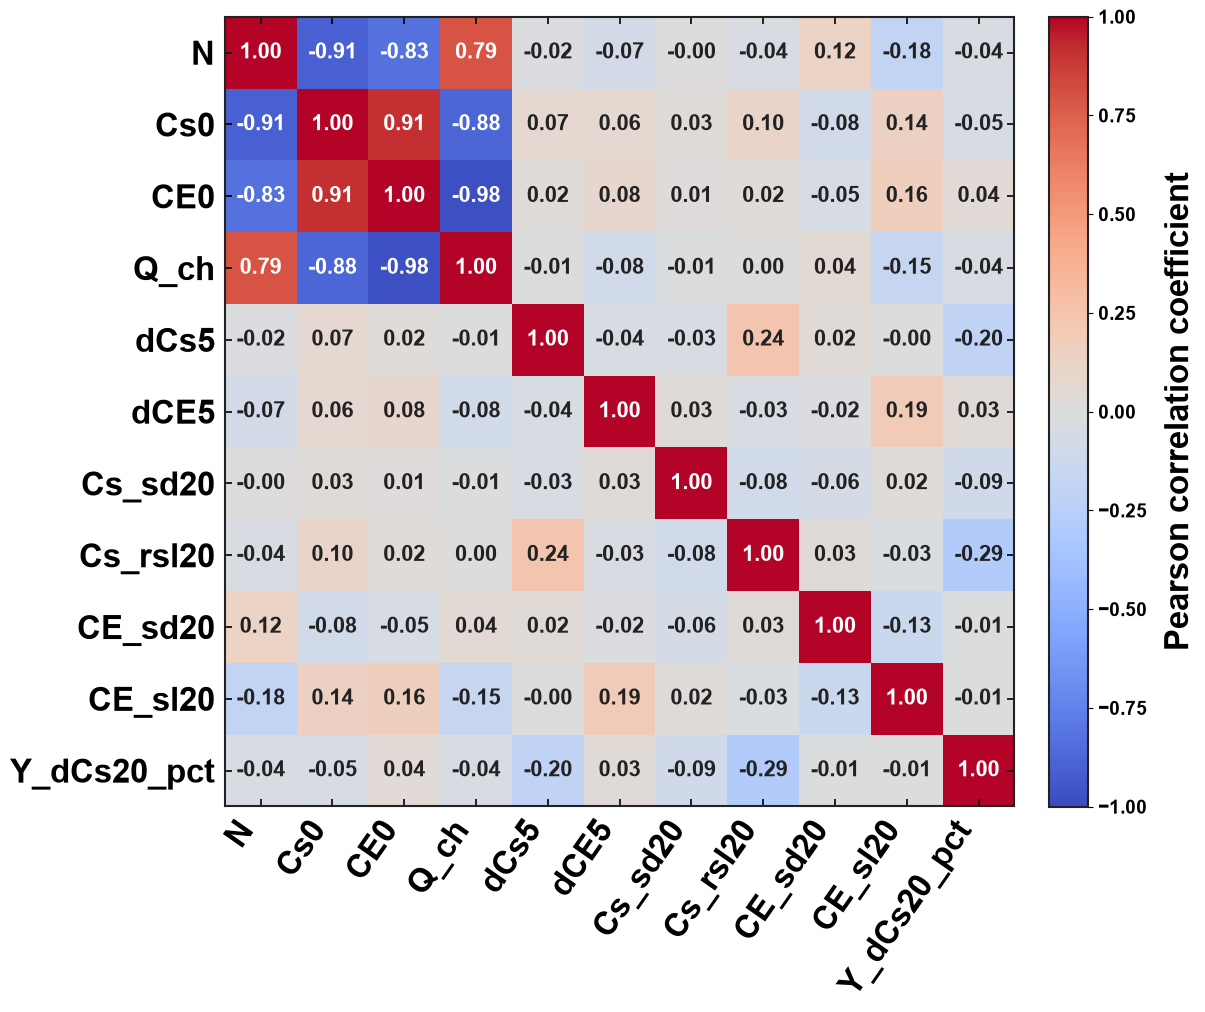

In [66]:

# ============================================================
# STEP 5 — PEARSON CORRELATION
# ============================================================

corr_columns = FEATURES + [TARGET]

pearson_matrix = train_df[
    corr_columns
].corr(method="pearson")

display(pearson_matrix.round(3))

pearson_matrix.to_excel(
    TABLE_DIR / "Pearson_Correlation_Train.xlsx"
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    pearson_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="equal"
)

n = len(corr_columns)

ax.set_xticks(np.arange(n))
ax.set_yticks(np.arange(n))

ax.set_xticklabels(
    corr_columns,
    rotation=55,
    ha="right",
    fontsize=24,
    fontweight="bold"
)

ax.set_yticklabels(
    corr_columns,
    fontsize=24,
    fontweight="bold"
)

# Correlation values
for i in range(n):
    for j in range(n):

        value = pearson_matrix.iloc[i, j]

        if np.isfinite(value):

            text_color = (
                "white" if abs(value) >= 0.65
                else COLOR_BLACK
            )

            ax.text(
                j, i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color=text_color
            )

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson correlation coefficient",
    fontsize=24,
    fontweight="bold",
    labelpad=12
)

for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")

frame_axes(ax)

fig.subplots_adjust(
    left=0.19,
    right=0.91,
    bottom=0.18,
    top=0.97
)

export_figure(fig, "Pearson_Correlation_Train")
plt.show()
plt.close(fig)


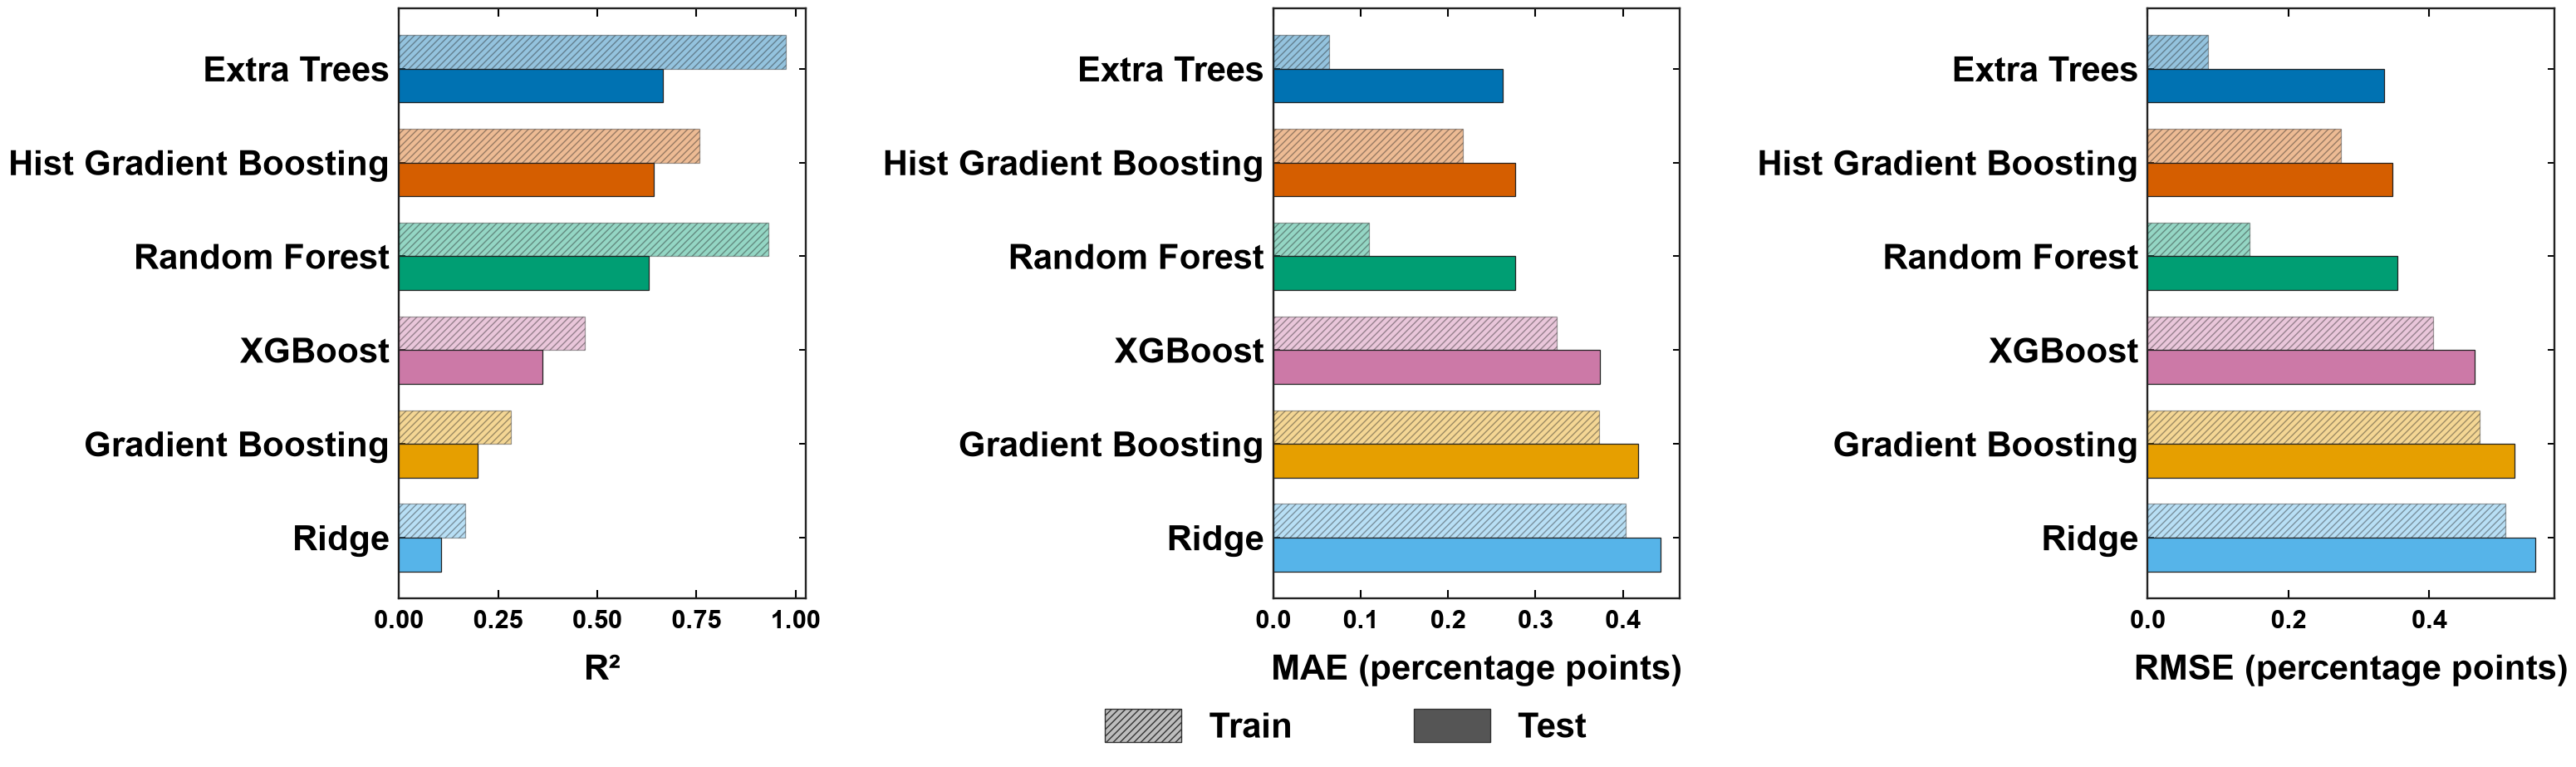

Figure exported successfully.
Output folder: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\ML_Standardized_Results\Figures
Figure size: 30 x 10 inches
Resolution: 600 dpi


In [69]:

# ============================================================
# STEP 7 — MODEL PERFORMANCE COMPARISON
# R², MAE AND RMSE — TRAIN vs TEST
# LARGE FIGURES, LARGE BOLD FONTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. FONT AND FIGURE SETTINGS
# ============================================================

FONT_MODEL = 30     # Model names on Y-axis
FONT_TICKS = 22       # Numerical values on X-axis
FONT_LABEL = 30       # X-axis labels
FONT_LEGEND = 30      # Train/Test legend

FIG_WIDTH = 30
FIG_HEIGHT = 10

# Horizontal spacing between panels
WSPACE = 1.15

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 24,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.linewidth": 1.7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.grid": False
})

# ============================================================
# 2. PREPARE METRICS
# ============================================================

# Requires metrics_df created in Step 6
required_cols = {"Model", "Split", "R2", "MAE", "RMSE"}

if "metrics_df" not in globals():
    raise NameError(
        "metrics_df is missing. Run Step 6 first."
    )

if not required_cols.issubset(metrics_df.columns):
    raise ValueError(
        f"Missing columns: "
        f"{required_cols - set(metrics_df.columns)}"
    )

train_metrics = (
    metrics_df[metrics_df["Split"] == "Train"]
    .set_index("Model")
)

test_metrics = (
    metrics_df[metrics_df["Split"] == "Test"]
    .set_index("Model")
)

model_names = (
    test_metrics.sort_values("RMSE").index.tolist()
)

if not model_names:
    raise ValueError("No Test metrics found.")

train_metrics = train_metrics.loc[model_names]
test_metrics = test_metrics.loc[model_names]

n_models = len(model_names)
y_pos = np.arange(n_models)

# ============================================================
# 3. MODEL COLORS
# ============================================================

PALETTE = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
    "#56B4E9",
    "#882255",
    "#44AA99",
    "#332288",
    "#AA4499",
    "#117733",
    "#999933"
]

EDGE_COLOR = "#222222"

# ============================================================
# 4. CREATE THREE LARGE PANELS
# ============================================================

fig = plt.figure(
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    facecolor="white"
)

gs = GridSpec(
    1, 3,
    figure=fig,

    left=0.12,
    right=0.985,

    bottom=0.25,
    top=0.96,

    wspace=WSPACE
)

axes = [
    fig.add_subplot(gs[0, i])
    for i in range(3)
]

bar_height = 0.36

metrics_info = [
    ("R2", "R²"),
    ("MAE", "MAE (percentage points)"),
    ("RMSE", "RMSE (percentage points)")
]

# ============================================================
# 5. DRAW TRAIN AND TEST BARS
# ============================================================

for ax, (metric, xlabel) in zip(
    axes, metrics_info
):

    train_values = train_metrics[metric].to_numpy()
    test_values = test_metrics[metric].to_numpy()

    for i, name in enumerate(model_names):

        color = PALETTE[i % len(PALETTE)]

        # TRAIN: light color + hatch
        ax.barh(
            y_pos[i] - bar_height / 2,
            train_values[i],

            height=bar_height,

            color=color,
            alpha=0.42,

            edgecolor=EDGE_COLOR,
            linewidth=0.9,

            hatch="////",
            zorder=3
        )

        # TEST: solid color
        ax.barh(
            y_pos[i] + bar_height / 2,
            test_values[i],

            height=bar_height,

            color=color,

            edgecolor=EDGE_COLOR,
            linewidth=0.9,

            zorder=3
        )

    # ========================================================
    # MODEL NAMES ON ALL THREE PANELS
    # ========================================================

    ax.set_yticks(y_pos)

    ax.set_yticklabels(
        model_names,
        fontsize=FONT_MODEL,
        fontweight="bold",
        ha="right"
    )

    ax.invert_yaxis()

    # ========================================================
    # X-AXIS LABELS
    # ========================================================

    ax.set_xlabel(
        xlabel,
        fontsize=FONT_LABEL,
        fontweight="bold",
        labelpad=18
    )

    # ========================================================
    # AXIS TICKS
    # ========================================================

    ax.tick_params(
        axis="x",
        labelsize=FONT_TICKS,
        direction="in",
        top=True,
        bottom=True,
        length=7,
        width=1.5,
        pad=10
    )

    ax.tick_params(
        axis="y",
        labelsize=FONT_MODEL,
        direction="in",
        left=True,
        right=True,
        length=6,
        width=1.4,
        pad=8
    )

    for label in ax.get_xticklabels():
        label.set_fontsize(FONT_TICKS)
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontsize(FONT_MODEL)
        label.set_fontweight("bold")

    # ========================================================
    # FOUR-SIDED AXIS FRAME
    # ========================================================

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.7)
        spine.set_color(EDGE_COLOR)

    if metric == "R2":
        ax.axvline(
            0,
            color=EDGE_COLOR,
            linewidth=1.1,
            zorder=2
        )

    ax.grid(False)

# ============================================================
# 6. ONE SHARED LEGEND
# ============================================================

legend_items = [
    Patch(
        facecolor="#BDBDBD",
        edgecolor="#333333",
        hatch="////",
        label="Train"
    ),

    Patch(
        facecolor="#555555",
        edgecolor="#333333",
        label="Test"
    )
]

legend = fig.legend(
    handles=legend_items,

    loc="center",
    bbox_to_anchor=(0.5, 0.095),
    bbox_transform=fig.transFigure,

    ncol=2,
    frameon=False,

    fontsize=FONT_LEGEND,

    handlelength=2.2,
    handleheight=1.1,
    columnspacing=3.5
)

for text in legend.get_texts():
    text.set_fontweight("bold")

# ============================================================
# 7. EXPORT FIGURE — 600 DPI
# ============================================================

FIG_DIR = Path.cwd() / "ML_Standardized_Results" / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

outname = FIG_DIR / "Model_Performance_Comparison_Large"

for ext in ["png", "tiff", "pdf"]:

    options = {
        "bbox_inches": "tight",
        "pad_inches": 0.20,
        "facecolor": "white"
    }

    if ext != "pdf":
        options["dpi"] = 600

    fig.savefig(
        str(outname) + f".{ext}",
        **options
    )

plt.show()
plt.close(fig)

print("Figure exported successfully.")
print("Output folder:", FIG_DIR)
print("Figure size:", FIG_WIDTH, "x", FIG_HEIGHT, "inches")
print("Resolution: 600 dpi")


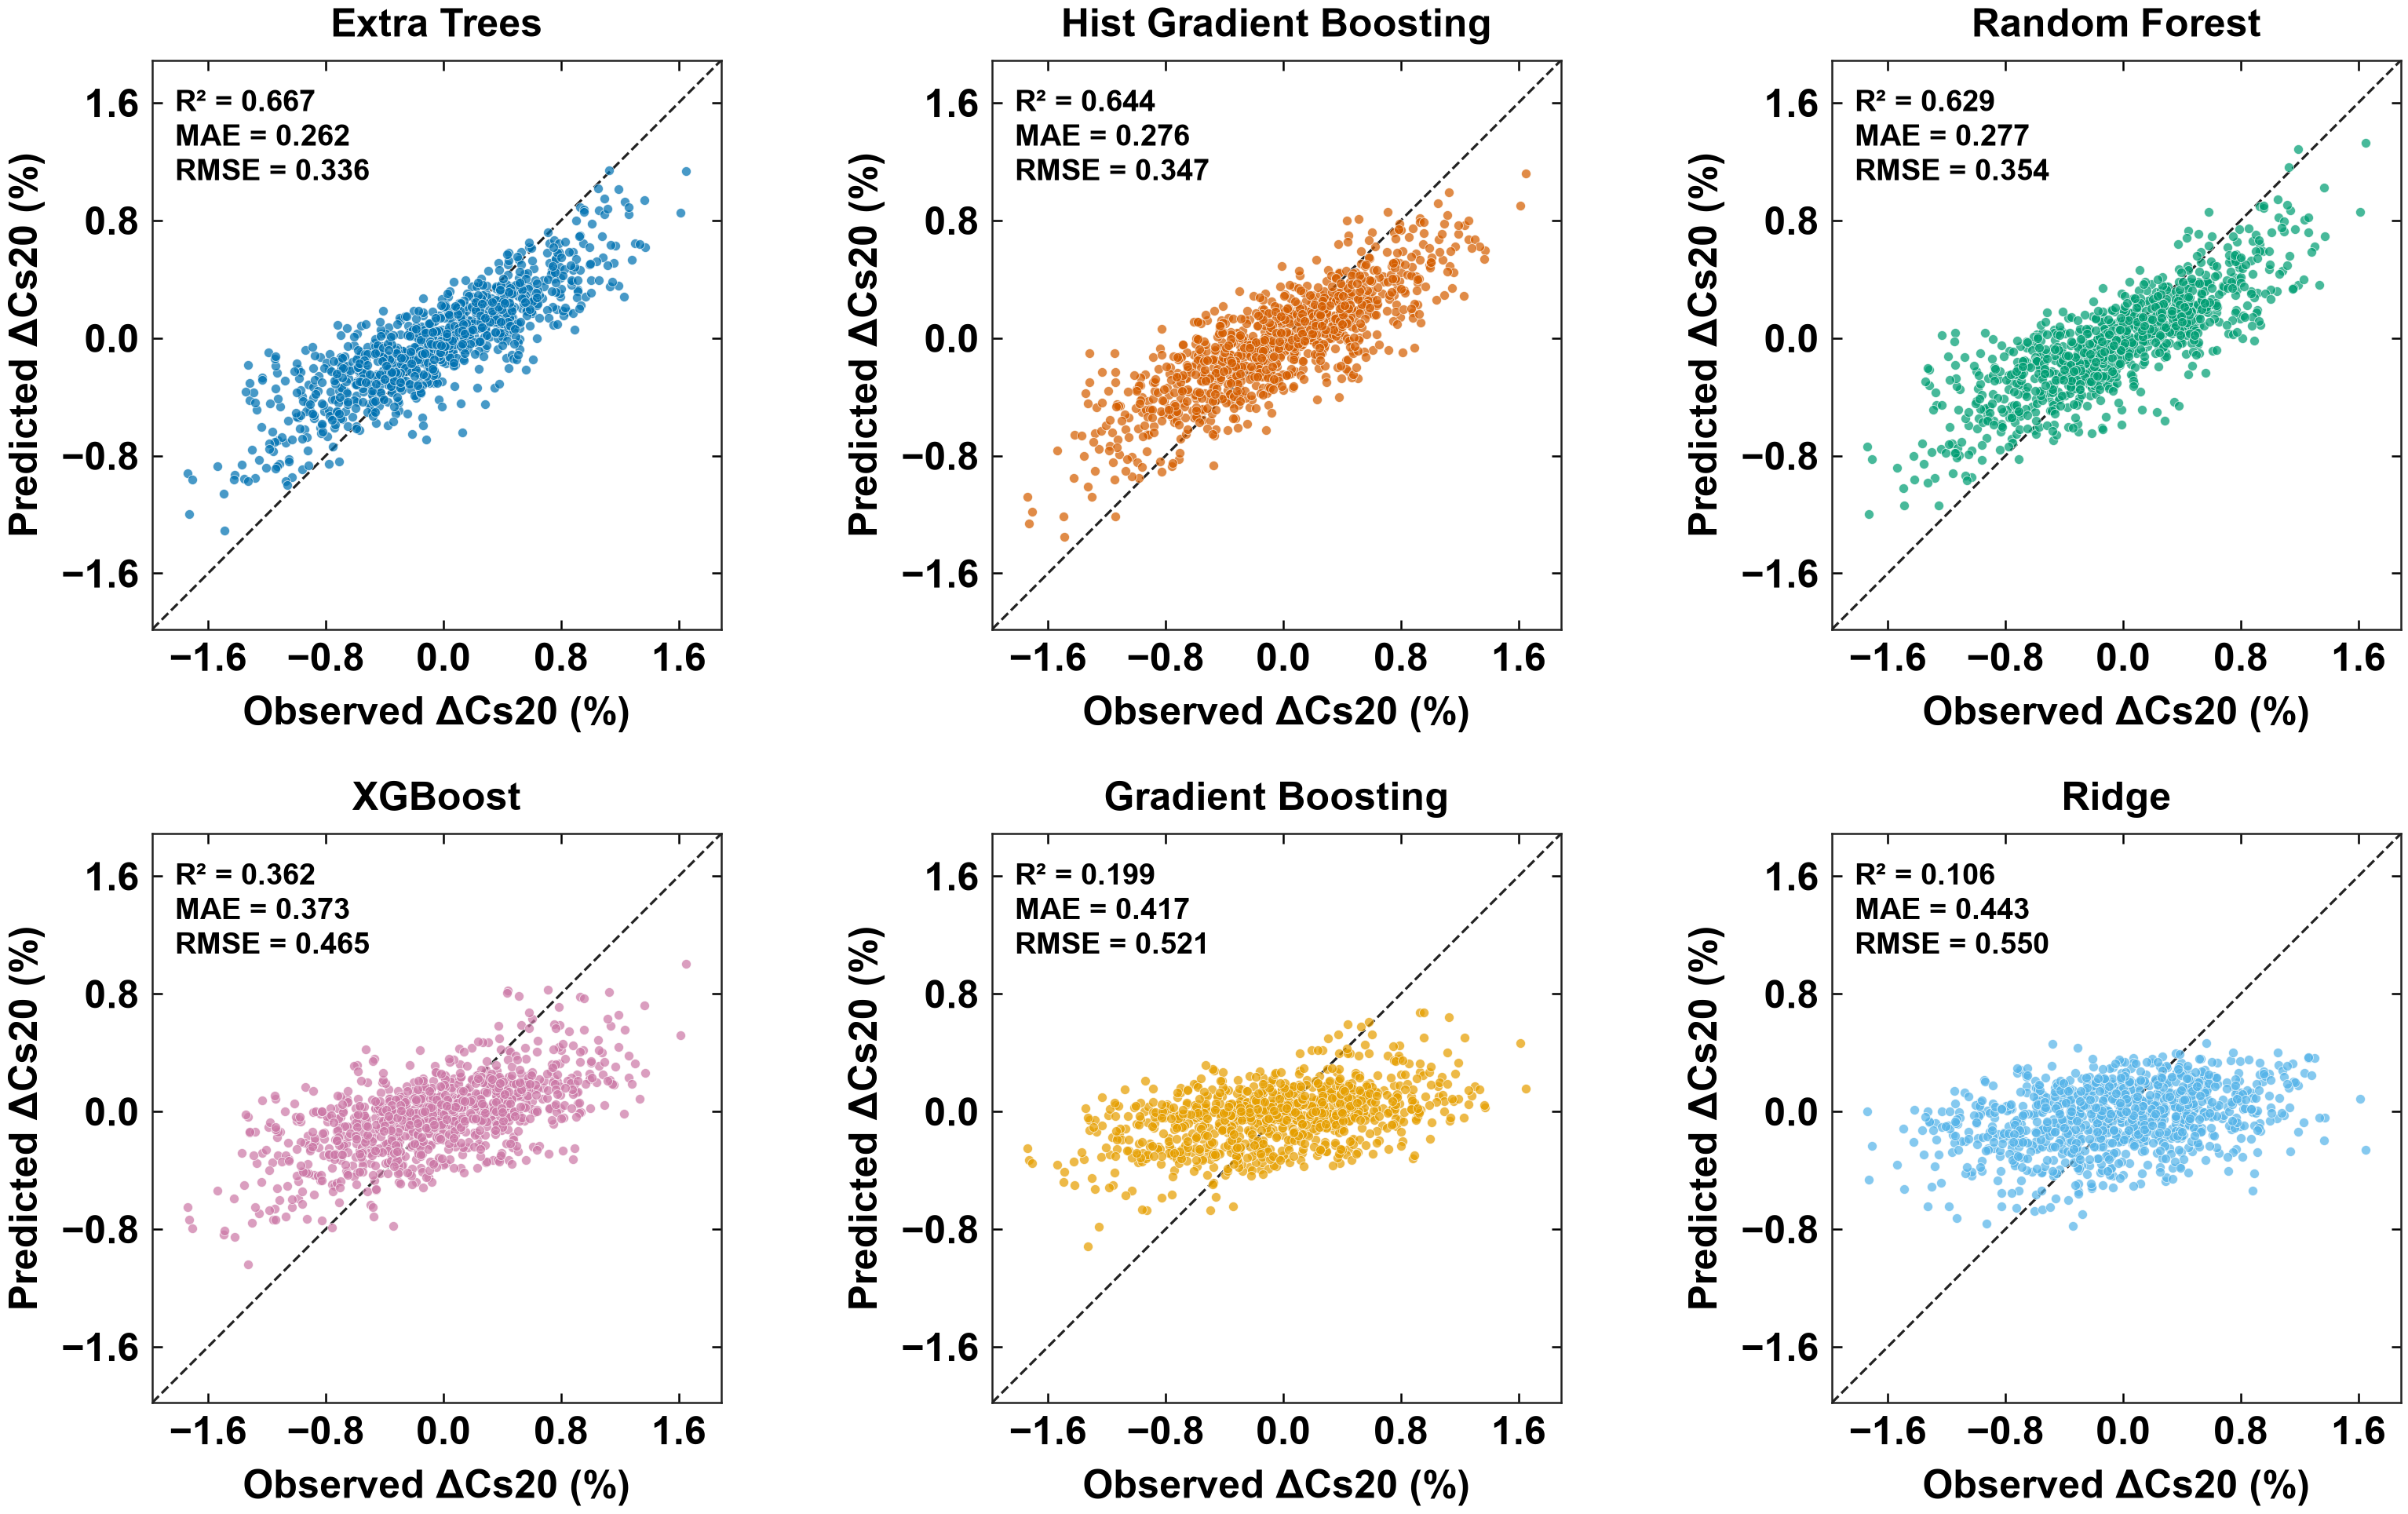

Parity plots exported successfully.
Output directory: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\ML_Standardized_Results\Figures


In [75]:

# ============================================================
# STEP 8 — TEST PARITY PLOTS FOR ALL MODELS
# LARGE PANELS | 32 PT BOLD FONTS | COMPACT LAYOUT
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import MaxNLocator

# ============================================================
# 1. FIGURE SETTINGS
# ============================================================

FONT_SIZE = 36
FONT_TITLE = 36
FONT_METRICS = 27

FIG_WIDTH = 33
ROW_HEIGHT = 10

# Distance between panels
WSPACE = 0.24
HSPACE = 0.36

ncols = 3
nrows = (len(model_names) + ncols - 1) // ncols

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.grid": False
})

# ============================================================
# 2. CREATE LARGE FIGURE
# ============================================================

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(FIG_WIDTH, ROW_HEIGHT * nrows),
    squeeze=False
)

axes_flat = axes.ravel()

# ============================================================
# 3. PARITY PLOTS
# ============================================================

for i, name in enumerate(model_names):

    ax = axes_flat[i]

    actual = np.asarray(y_test).ravel()
    prediction = np.asarray(pred_test[name]).ravel()

    model_color = PALETTE[i % len(PALETTE)]

    # --------------------------------------------------------
    # Scatter
    # --------------------------------------------------------

    ax.scatter(
        actual,
        prediction,
        s=75,
        alpha=0.72,
        color=model_color,
        edgecolor="white",
        linewidth=0.6,
        rasterized=True,
        zorder=3
    )

    # --------------------------------------------------------
    # Equal axis limits
    # --------------------------------------------------------

    lower = min(actual.min(), prediction.min())
    upper = max(actual.max(), prediction.max())

    padding = max(
        (upper - lower) * 0.07,
        1e-6
    )

    limits = (
        lower - padding,
        upper + padding
    )

    # Ideal prediction line
    ax.plot(
        limits,
        limits,
        linestyle="--",
        color="#222222",
        linewidth=2.3,
        zorder=2
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")

    # --------------------------------------------------------
    # Model title
    # --------------------------------------------------------

    ax.set_title(
        name,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=22
    )

    # --------------------------------------------------------
    # Performance metrics inside plot
    # --------------------------------------------------------

    row = test_metrics.loc[name]

    metrics_text = (
        f"R² = {row['R2']:.3f}\n"
        f"MAE = {row['MAE']:.3f}\n"
        f"RMSE = {row['RMSE']:.3f}"
    )

    ax.text(
        0.04,
        0.96,
        metrics_text,
        transform=ax.transAxes,
        fontsize=FONT_METRICS,
        fontweight="bold",
        va="top",
        ha="left",
        linespacing=1.25,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.82,
            boxstyle="round,pad=0.25"
        ),
        zorder=5
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xlabel(
        "Observed ΔCs20 (%)",
        fontsize=FONT_SIZE,
        fontweight="bold",
        labelpad=15
    )

    ax.set_ylabel(
        "Predicted ΔCs20 (%)",
        fontsize=FONT_SIZE,
        fontweight="bold",
        labelpad=15
    )

    # --------------------------------------------------------
    # Ticks
    # --------------------------------------------------------

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax.tick_params(
        axis="both",
        labelsize=FONT_SIZE,
        direction="in",
        top=True,
        right=True,
        length=9,
        width=1.8,
        pad=12
    )

    for label in ax.get_xticklabels():
        label.set_fontsize(FONT_SIZE)
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontsize(FONT_SIZE)
        label.set_fontweight("bold")

    # --------------------------------------------------------
    # Four-sided frame
    # --------------------------------------------------------

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.8)
        spine.set_color("#222222")

    ax.grid(False)

# ============================================================
# 4. HIDE UNUSED PANELS
# ============================================================

for i in range(len(model_names), len(axes_flat)):
    axes_flat[i].set_visible(False)

# ============================================================
# 5. ADJUST PANEL POSITIONS
# ============================================================

fig.subplots_adjust(
    left=0.075,
    right=0.985,
    bottom=0.085,
    top=0.94,
    wspace=WSPACE,
    hspace=HSPACE
)

# ============================================================
# 6. EXPORT — PNG, TIFF, PDF
# ============================================================

FIG_DIR = (
    Path.cwd()
    / "ML_Standardized_Results"
    / "Figures"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

outname = FIG_DIR / "Test_Parity_All_Models_Large"

for ext in ["png", "tiff", "pdf"]:

    options = {
        "bbox_inches": "tight",
        "pad_inches": 0.18,
        "facecolor": "white"
    }

    if ext != "pdf":
        options["dpi"] = 600

    fig.savefig(
        str(outname) + f".{ext}",
        **options
    )

plt.show()
plt.close(fig)

print("Parity plots exported successfully.")
print("Output directory:", FIG_DIR)


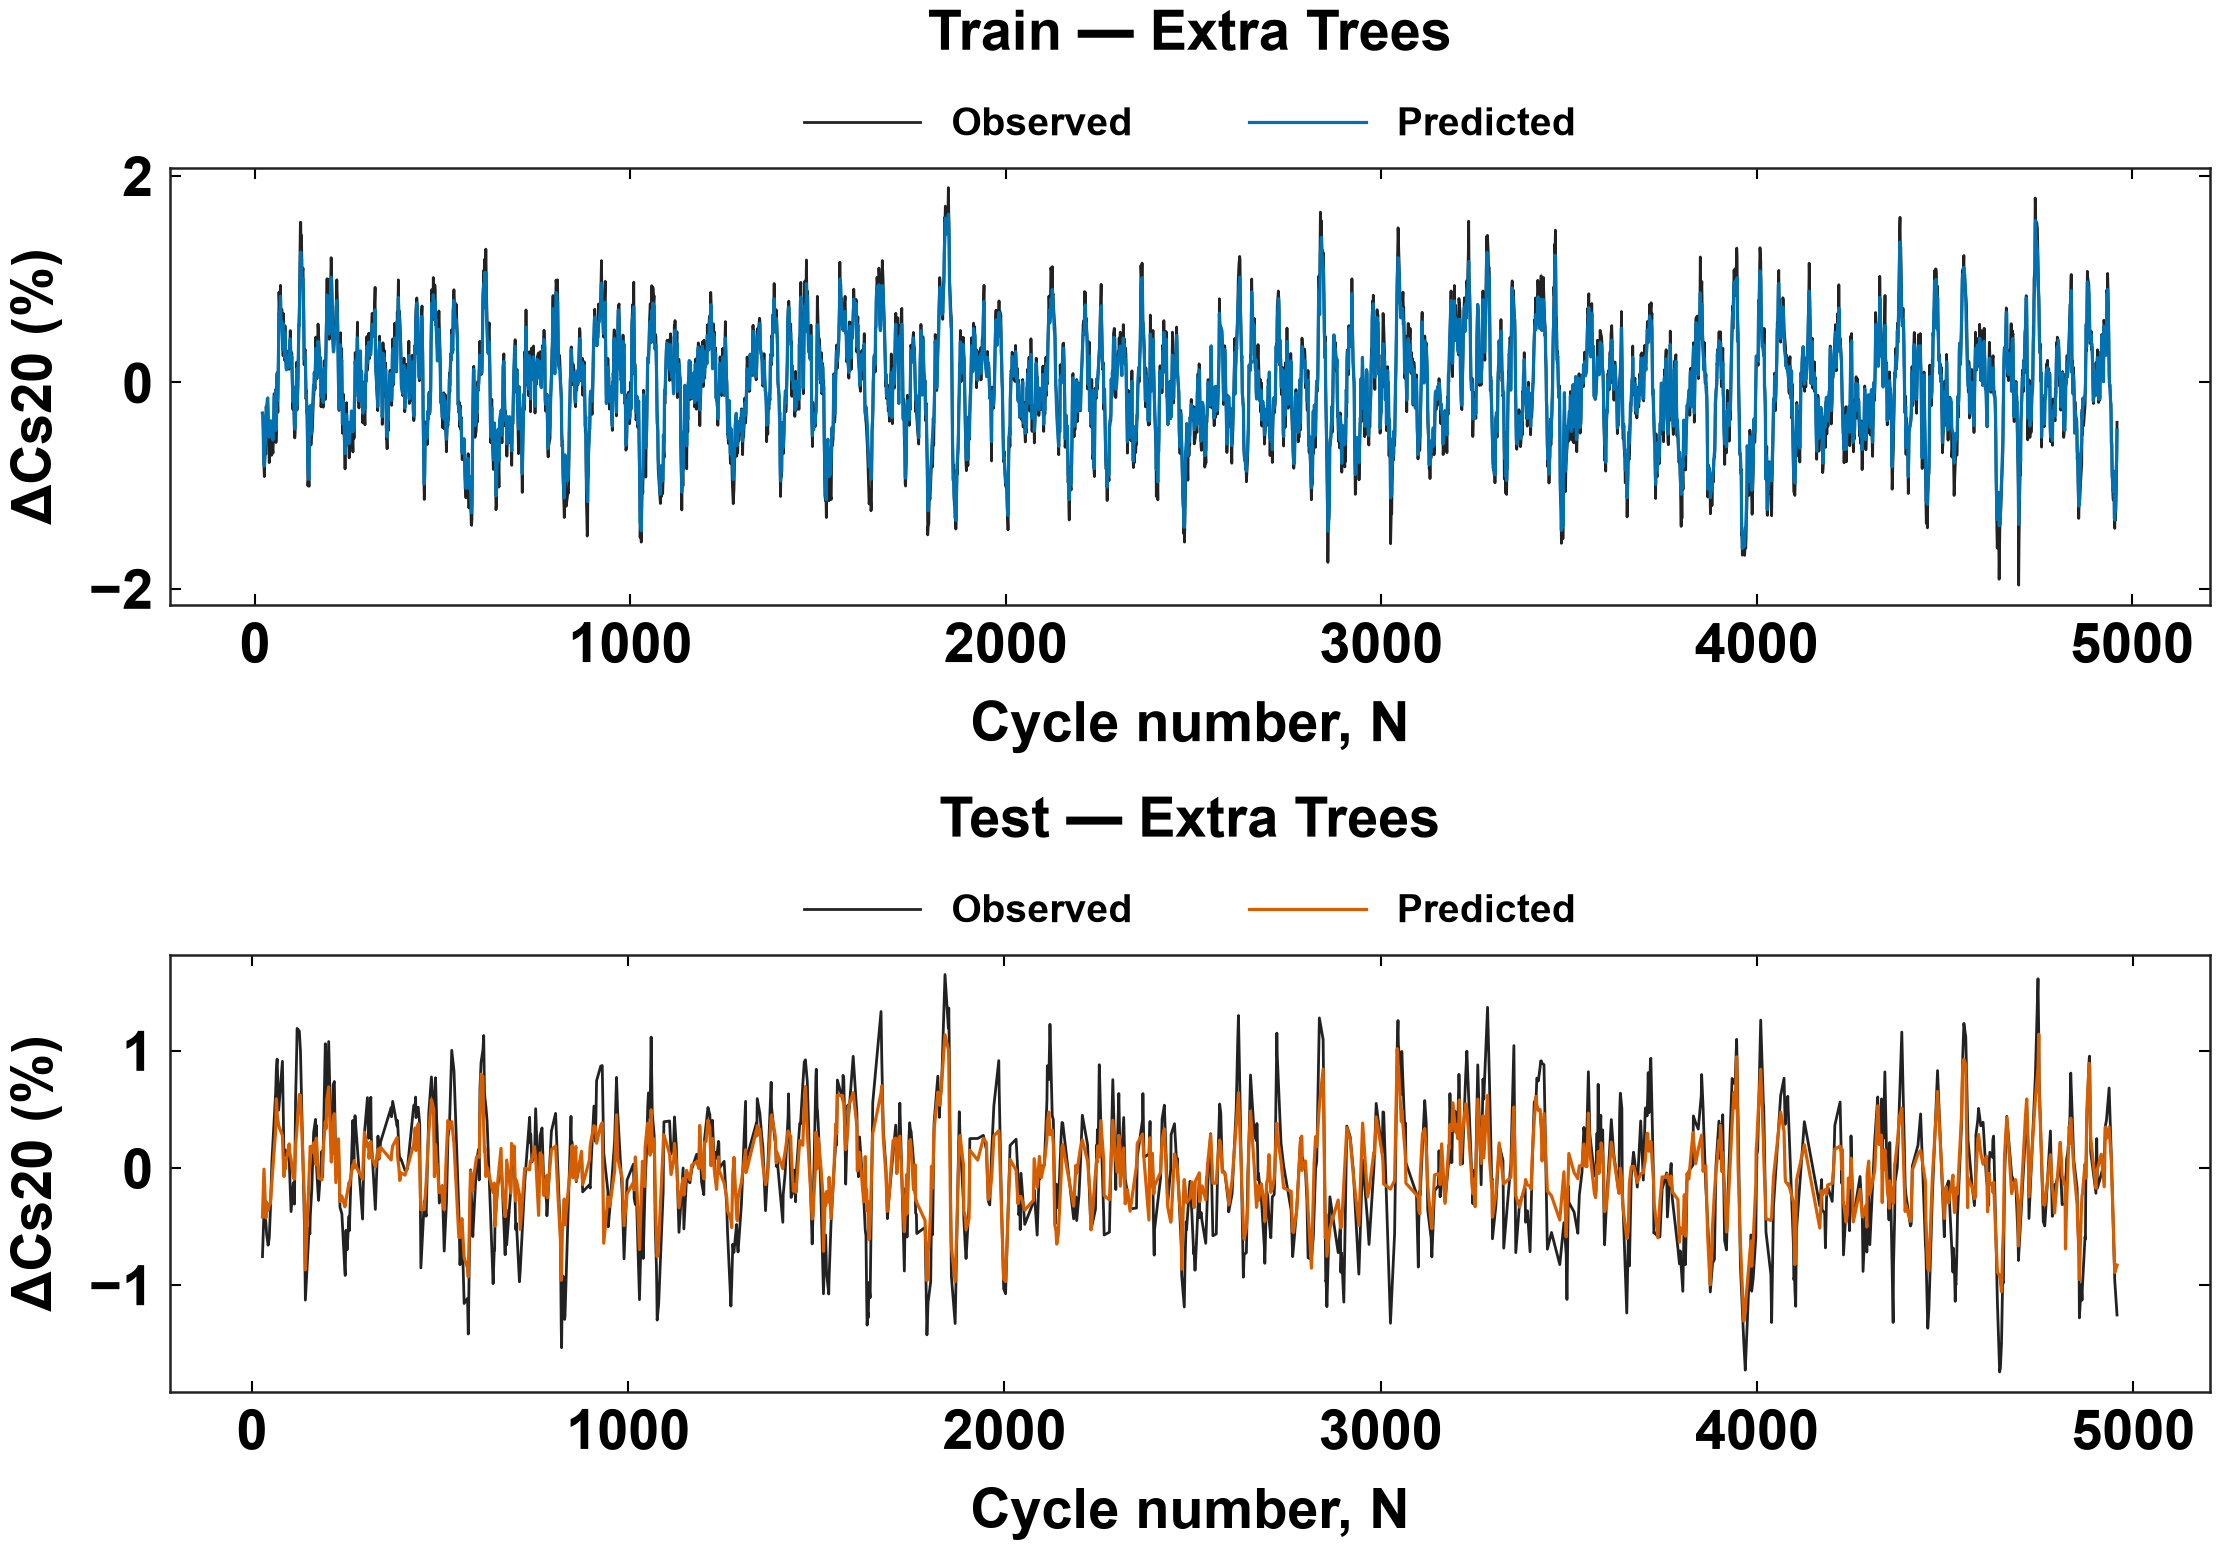

Figure exported successfully.
Saved to: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\ML_Standardized_Results\Figures


In [77]:

# ============================================================
# STEP 9 — OBSERVED VS PREDICTED ACROSS CYCLES
# LEGEND ABOVE EACH PANEL — NO OVERLAPPING
# LARGE BOLD FONTS — 30 PT
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. FIGURE SETTINGS
# ============================================================

FONT_SIZE = 40
FONT_TITLE = 40
FONT_LEGEND = 28

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.grid": False
})

# ============================================================
# 2. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(24, 17)
)

plot_parts = [
    (
        axes[0],
        train_df,
        pred_train[best_name],
        "Train",
        COLOR_TRAIN
    ),
    (
        axes[1],
        test_df,
        pred_test[best_name],
        "Test",
        COLOR_TEST
    )
]

# ============================================================
# 3. DRAW OBSERVED AND PREDICTED
# ============================================================

for ax, part, prediction, split, color in plot_parts:

    # Sort by cycle number
    order = np.argsort(
        part["N"].to_numpy()
    )

    cycles = part["N"].to_numpy()[order]
    observed = part[TARGET].to_numpy()[order]
    predicted = np.asarray(prediction).ravel()[order]

    # Observed
    ax.plot(
        cycles,
        observed,
        color=COLOR_BLACK,
        linewidth=2.0,
        label="Observed",
        zorder=2
    )

    # Predicted
    ax.plot(
        cycles,
        predicted,
        color=color,
        linewidth=2.3,
        label="Predicted",
        zorder=3
    )

    # Panel title
    ax.set_title(
        f"{split} — {best_name}",
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=85
    )

    # Axis labels
    ax.set_xlabel(
        "Cycle number, N",
        fontsize=FONT_SIZE,
        fontweight="bold",
        labelpad=19
    )

    ax.set_ylabel(
        "ΔCs20 (%)",
        fontsize=FONT_SIZE,
        fontweight="bold",
        labelpad=19
    )

    # ========================================================
    # LEGEND OUTSIDE THE PLOTTING AREA
    # ========================================================

    legend = ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=2,
        frameon=False,
        fontsize=FONT_LEGEND,
        handlelength=3.0,
        columnspacing=3.0,
        borderaxespad=0
    )

    for text in legend.get_texts():
        text.set_fontweight("bold")

    # Four-sided frame
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.8)
        spine.set_color("#222222")

    # Tick labels
    ax.tick_params(
        axis="both",
        labelsize=FONT_SIZE,
        direction="in",
        top=True,
        right=True,
        length=8,
        width=1.5,
        pad=12
    )

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.grid(False)

# ============================================================
# 4. ADJUST SPACING
# ============================================================

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    bottom=0.10,
    top=0.82,
    hspace=0.80
)

# ============================================================
# 5. EXPORT FIGURE
# ============================================================

FIG_DIR = (
    Path.cwd()
    / "ML_Standardized_Results"
    / "Figures"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

outname = FIG_DIR / "Observed_Predicted_Cycles_30pt"

for ext in ["png", "tiff", "pdf"]:

    options = {
        "bbox_inches": "tight",
        "pad_inches": 0.20,
        "facecolor": "white"
    }

    if ext != "pdf":
        options["dpi"] = 600

    fig.savefig(
        str(outname) + f".{ext}",
        **options
    )

plt.show()
plt.close(fig)

print("Figure exported successfully.")
print("Saved to:", FIG_DIR)


Exported: Residual_Distribution_30pt


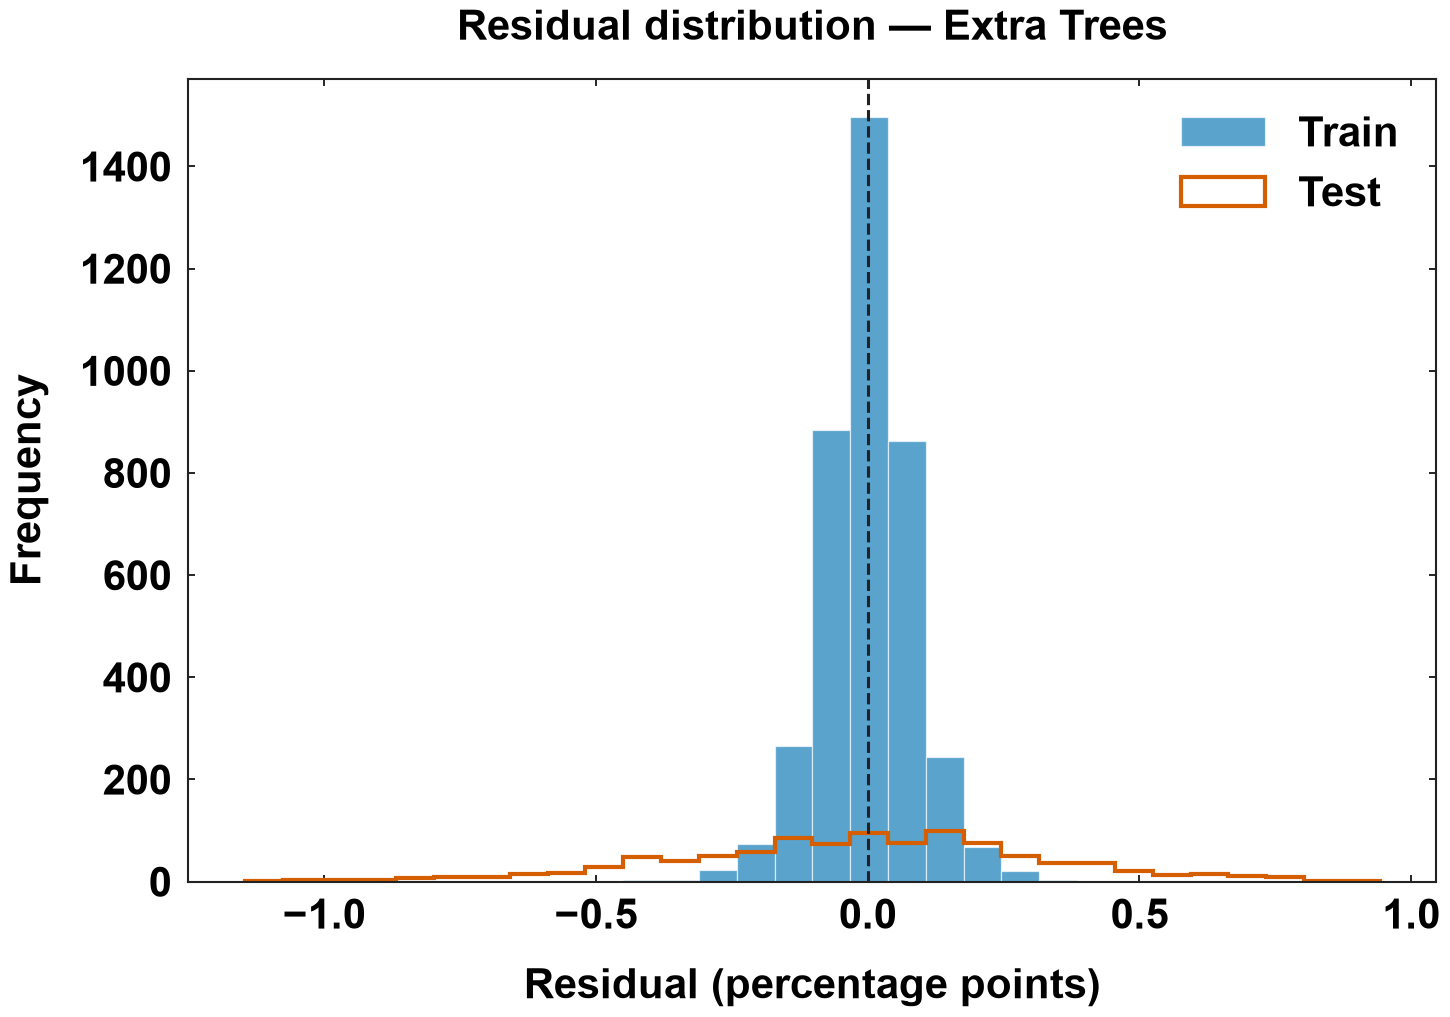

In [80]:

# ============================================================
# STEP 10 — RESIDUAL DISTRIBUTION
# ALL FONTS 30 PT, BOLD
# ============================================================

FONT_SIZE = 30

residual_train = (
    np.asarray(y_train).ravel()
    - np.asarray(pred_train[best_name]).ravel()
)

residual_test = (
    np.asarray(y_test).ravel()
    - np.asarray(pred_test[best_name]).ravel()
)

bins = np.histogram_bin_edges(
    np.concatenate([residual_train, residual_test]),
    bins=30
)

fig, ax = plt.subplots(figsize=(16, 11))

ax.hist(
    residual_train,
    bins=bins,
    alpha=0.65,
    color=COLOR_TRAIN,
    edgecolor="white",
    linewidth=0.9,
    label="Train"
)

ax.hist(
    residual_test,
    bins=bins,
    histtype="step",
    linewidth=3,
    color=COLOR_TEST,
    label="Test"
)

ax.axvline(
    0,
    linestyle="--",
    color=COLOR_BLACK,
    linewidth=2.2
)

ax.set_xlabel(
    "Residual (percentage points)",
    fontsize=FONT_SIZE,
    fontweight="bold",
    labelpad=22
)

ax.set_ylabel(
    "Frequency",
    fontsize=FONT_SIZE,
    fontweight="bold",
    labelpad=22
)

ax.set_title(
    f"Residual distribution — {best_name}",
    fontsize=FONT_SIZE,
    fontweight="bold",
    pad=28
)

legend = ax.legend(
    loc="best",
    frameon=False,
    fontsize=FONT_SIZE
)

for text in legend.get_texts():
    text.set_fontweight("bold")

frame_axes(ax)

ax.tick_params(
    axis="both",
    labelsize=FONT_SIZE,
    pad=12
)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")

fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.17,
    top=0.90
)

export_figure(
    fig,
    "Residual_Distribution_30pt"
)

plt.show()
plt.close(fig)


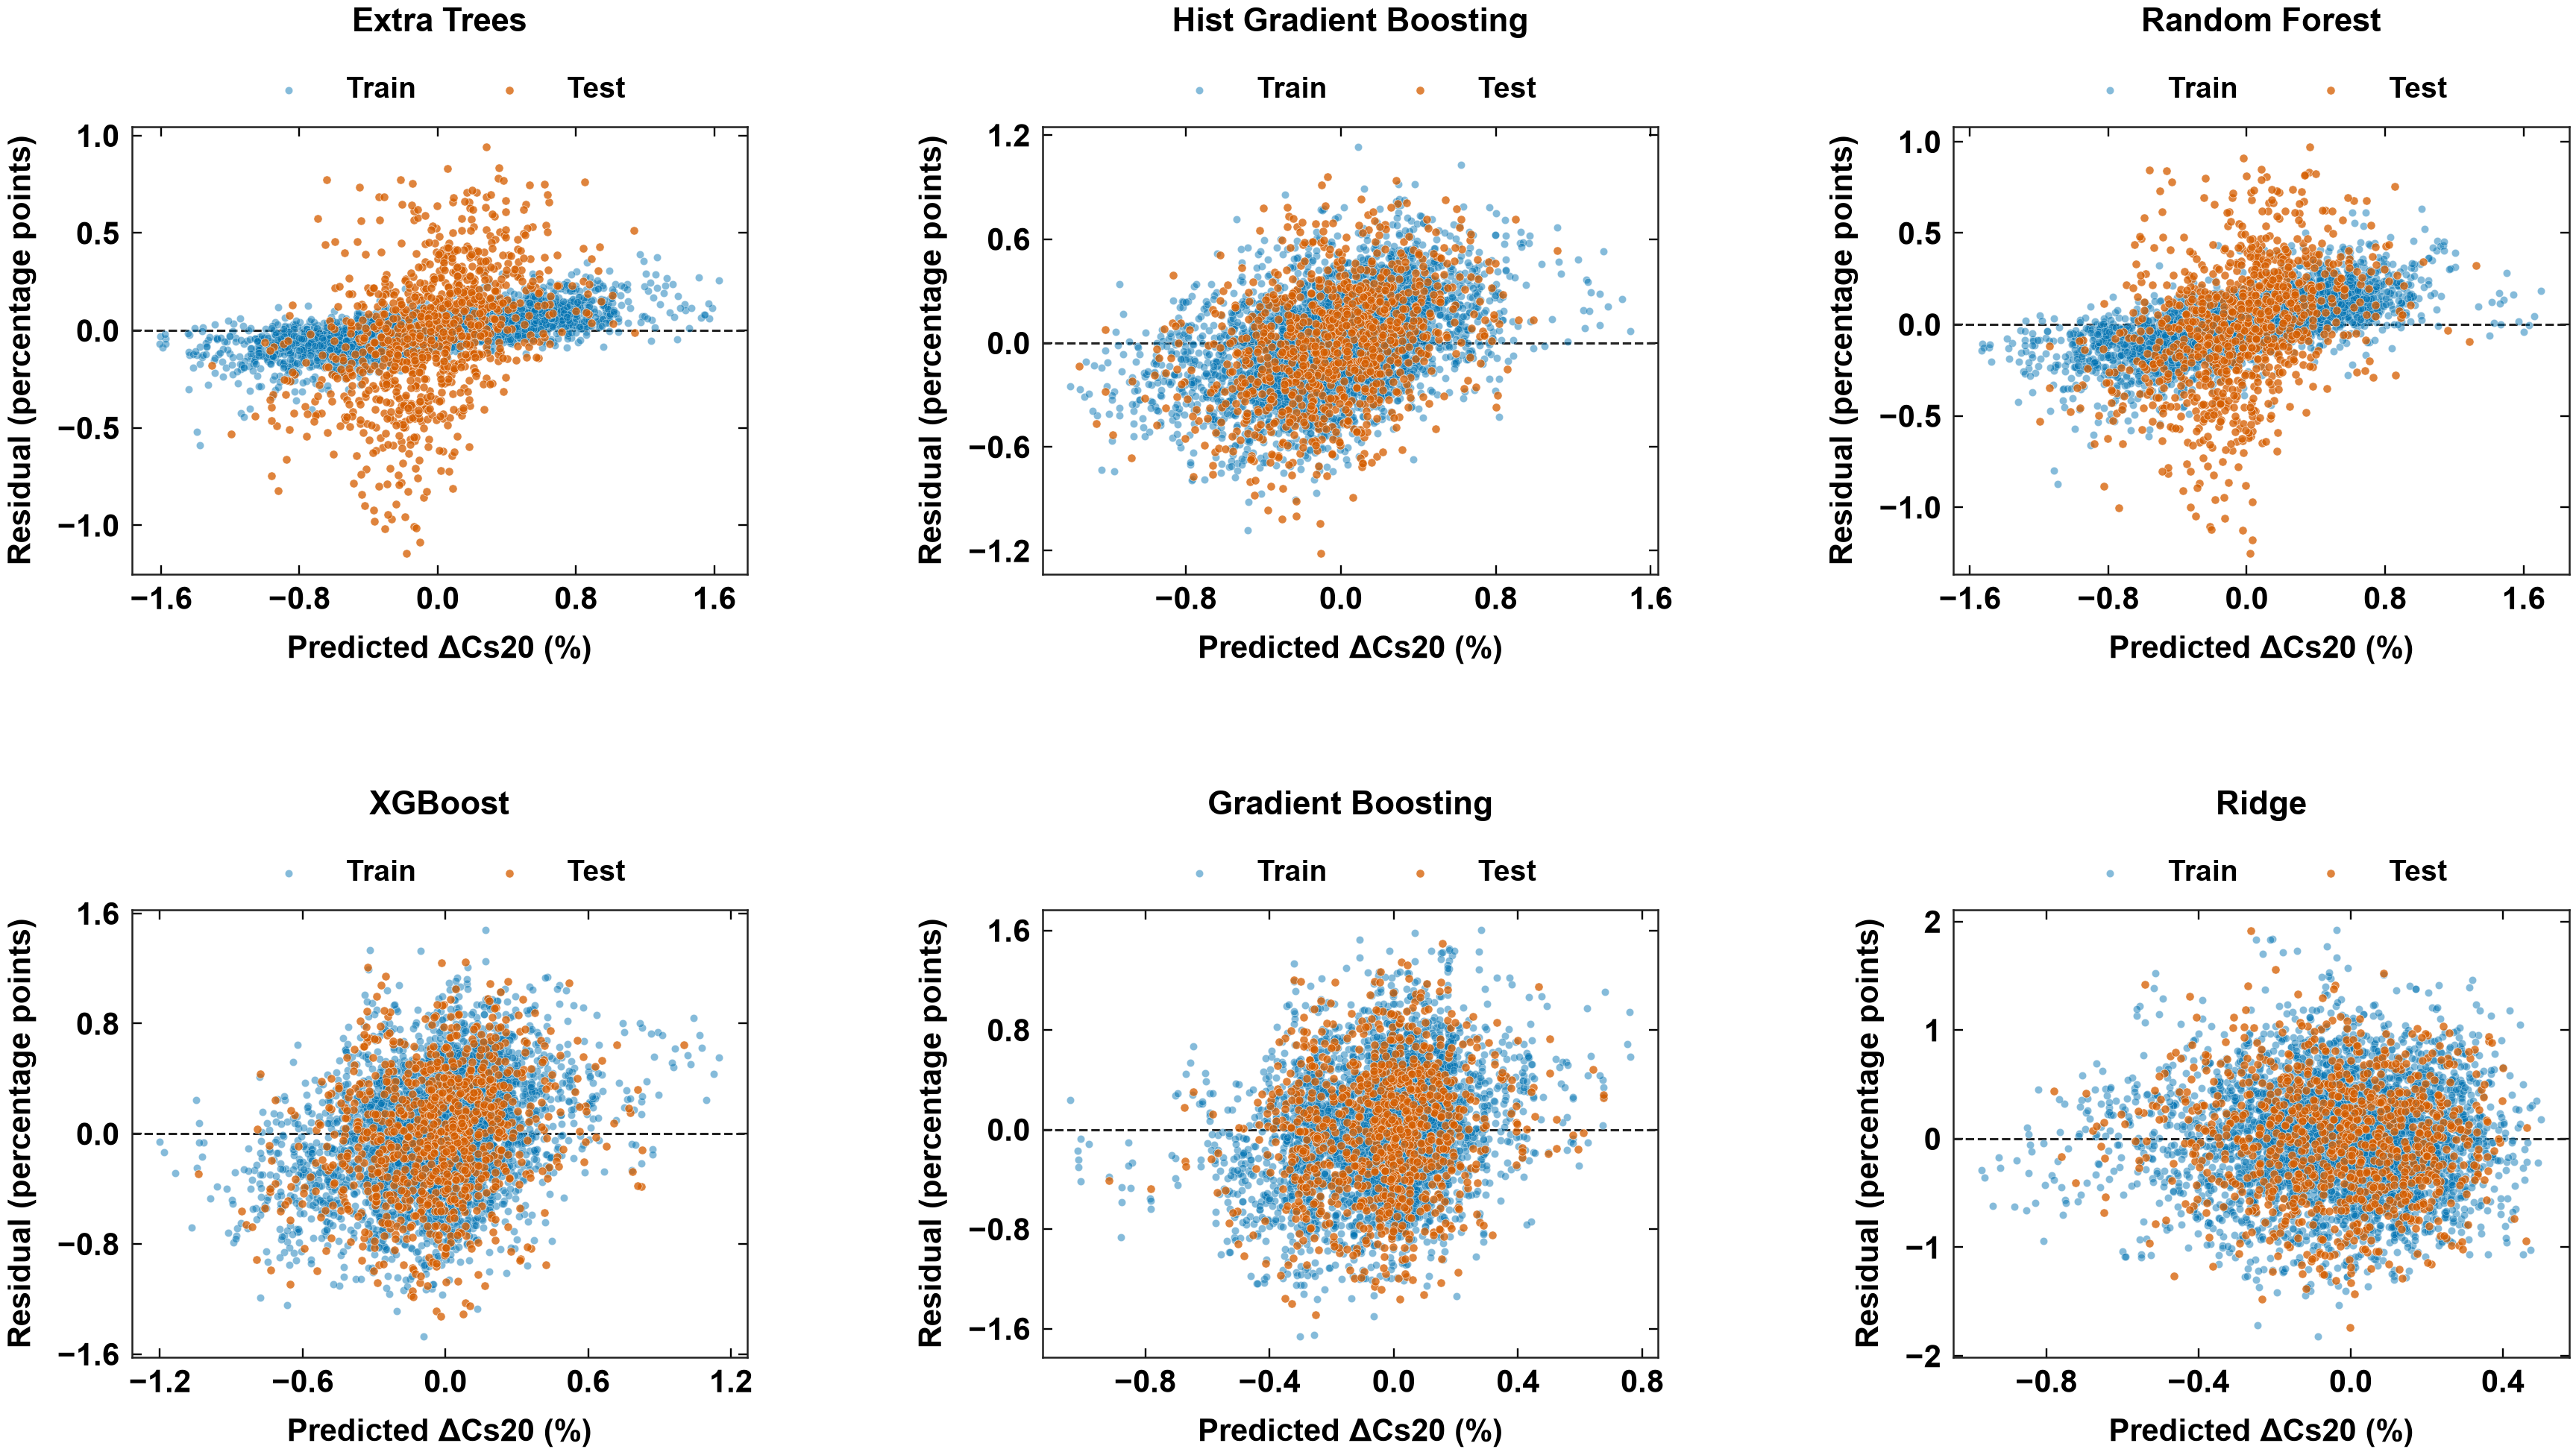

Residual plots exported successfully.
Output directory: c:\Users\Luong T. C. Pham\OneDrive\Desktop\ML Tea Waste\ML_Standardized_Results\Figures


In [81]:

# ============================================================
# STEP 11 — RESIDUAL VS PREDICTED FOR ALL MODELS
# LARGE 30 PT BOLD FONTS
# LEGEND ABOVE EACH PANEL — NO OVERLAPPING
# BALANCED 2 × 3 LAYOUT
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import MaxNLocator

# ============================================================
# 1. FIGURE SETTINGS
# ============================================================

FONT_SIZE = 30
FONT_TITLE = 32
FONT_LEGEND = 28

FIG_WIDTH = 38
ROW_HEIGHT = 11

# Layout settings
WSPACE = 0.48
HSPACE = 0.75

COLOR_TRAIN = "#0072B2"
COLOR_TEST = "#D55E00"
COLOR_BLACK = "#222222"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.grid": False
})

# ============================================================
# 2. CREATE FIGURE
# ============================================================

ncols = 3
nrows = (len(model_names) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(FIG_WIDTH, ROW_HEIGHT * nrows),
    squeeze=False,
    facecolor="white"
)

axes_flat = axes.ravel()

# ============================================================
# 3. DRAW RESIDUAL PLOTS
# ============================================================

for i, name in enumerate(model_names):

    ax = axes_flat[i]

    prediction_train = np.asarray(
        pred_train[name]
    ).ravel()

    prediction_test = np.asarray(
        pred_test[name]
    ).ravel()

    actual_train = np.asarray(y_train).ravel()
    actual_test = np.asarray(y_test).ravel()

    train_residual = actual_train - prediction_train
    test_residual = actual_test - prediction_test

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    ax.scatter(
        prediction_train,
        train_residual,
        s=55,
        alpha=0.48,
        color=COLOR_TRAIN,
        edgecolor="white",
        linewidth=0.45,
        label="Train",
        rasterized=True,
        zorder=3
    )

    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------

    ax.scatter(
        prediction_test,
        test_residual,
        s=65,
        alpha=0.76,
        color=COLOR_TEST,
        edgecolor="white",
        linewidth=0.5,
        label="Test",
        rasterized=True,
        zorder=4
    )

    # --------------------------------------------------------
    # ZERO RESIDUAL REFERENCE
    # --------------------------------------------------------

    ax.axhline(
        0,
        color=COLOR_BLACK,
        linestyle="--",
        linewidth=2.2,
        zorder=2
    )

    # --------------------------------------------------------
    # MODEL TITLE
    # --------------------------------------------------------

    ax.set_title(
        name,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=92
    )

    # --------------------------------------------------------
    # AXIS LABELS
    # --------------------------------------------------------

    ax.set_xlabel(
        "Predicted ΔCs20 (%)",
        fontsize=FONT_SIZE,
        fontweight="bold",
        labelpad=19
    )

    ax.set_ylabel(
        "Residual (percentage points)",
        fontsize=FONT_SIZE,
        fontweight="bold",
        labelpad=20
    )

    # --------------------------------------------------------
    # LEGEND ABOVE PLOT
    # --------------------------------------------------------

    legend = ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.025),
        ncol=2,
        frameon=False,
        fontsize=FONT_LEGEND,
        handlelength=2.4,
        columnspacing=2.0,
        borderaxespad=0
    )

    for text in legend.get_texts():
        text.set_fontweight("bold")

    # --------------------------------------------------------
    # AXIS TICKS
    # --------------------------------------------------------

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax.tick_params(
        axis="both",
        labelsize=FONT_SIZE,
        direction="in",
        top=True,
        right=True,
        length=9,
        width=1.7,
        pad=12
    )

    for label in ax.get_xticklabels():
        label.set_fontsize(FONT_SIZE)
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontsize(FONT_SIZE)
        label.set_fontweight("bold")

    # --------------------------------------------------------
    # FOUR-SIDED FRAME
    # --------------------------------------------------------

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.8)
        spine.set_color(COLOR_BLACK)

    ax.grid(False)

# ============================================================
# 4. HIDE UNUSED PANELS
# ============================================================

for i in range(len(model_names), len(axes_flat)):
    axes_flat[i].set_visible(False)

# ============================================================
# 5. ADJUST SPACING
# ============================================================

fig.subplots_adjust(
    left=0.12,
    right=0.98,
    bottom=0.09,
    top=0.84,
    wspace=WSPACE,
    hspace=HSPACE
)

# ============================================================
# 6. EXPORT FIGURES
# ============================================================

FIG_DIR = (
    Path.cwd()
    / "ML_Standardized_Results"
    / "Figures"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

outname = FIG_DIR / "Residual_vs_Predicted_All_Models_30pt"

for ext in ["png", "tiff", "pdf"]:

    options = {
        "bbox_inches": "tight",
        "pad_inches": 0.20,
        "facecolor": "white"
    }

    if ext != "pdf":
        options["dpi"] = 600

    fig.savefig(
        str(outname) + f".{ext}",
        **options
    )

plt.show()
plt.close(fig)

print("Residual plots exported successfully.")
print("Output directory:", FIG_DIR)


PermutationExplainer explainer: 201it [00:21,  5.17it/s]                         


,Feature,Mean_abs_SHAP
1,Cs0,0.117157
7,Cs_rsl20,0.106506
0,N,0.090927
3,Q_ch,0.075653
4,dCs5,0.048850
2,CE0,0.043601
6,Cs_sd20,0.031208
8,CE_sd20,0.030376
9,CE_sl20,0.022578
5,dCE5,0.008780


Exported: SHAP_Feature_Importance_Summary_30pt


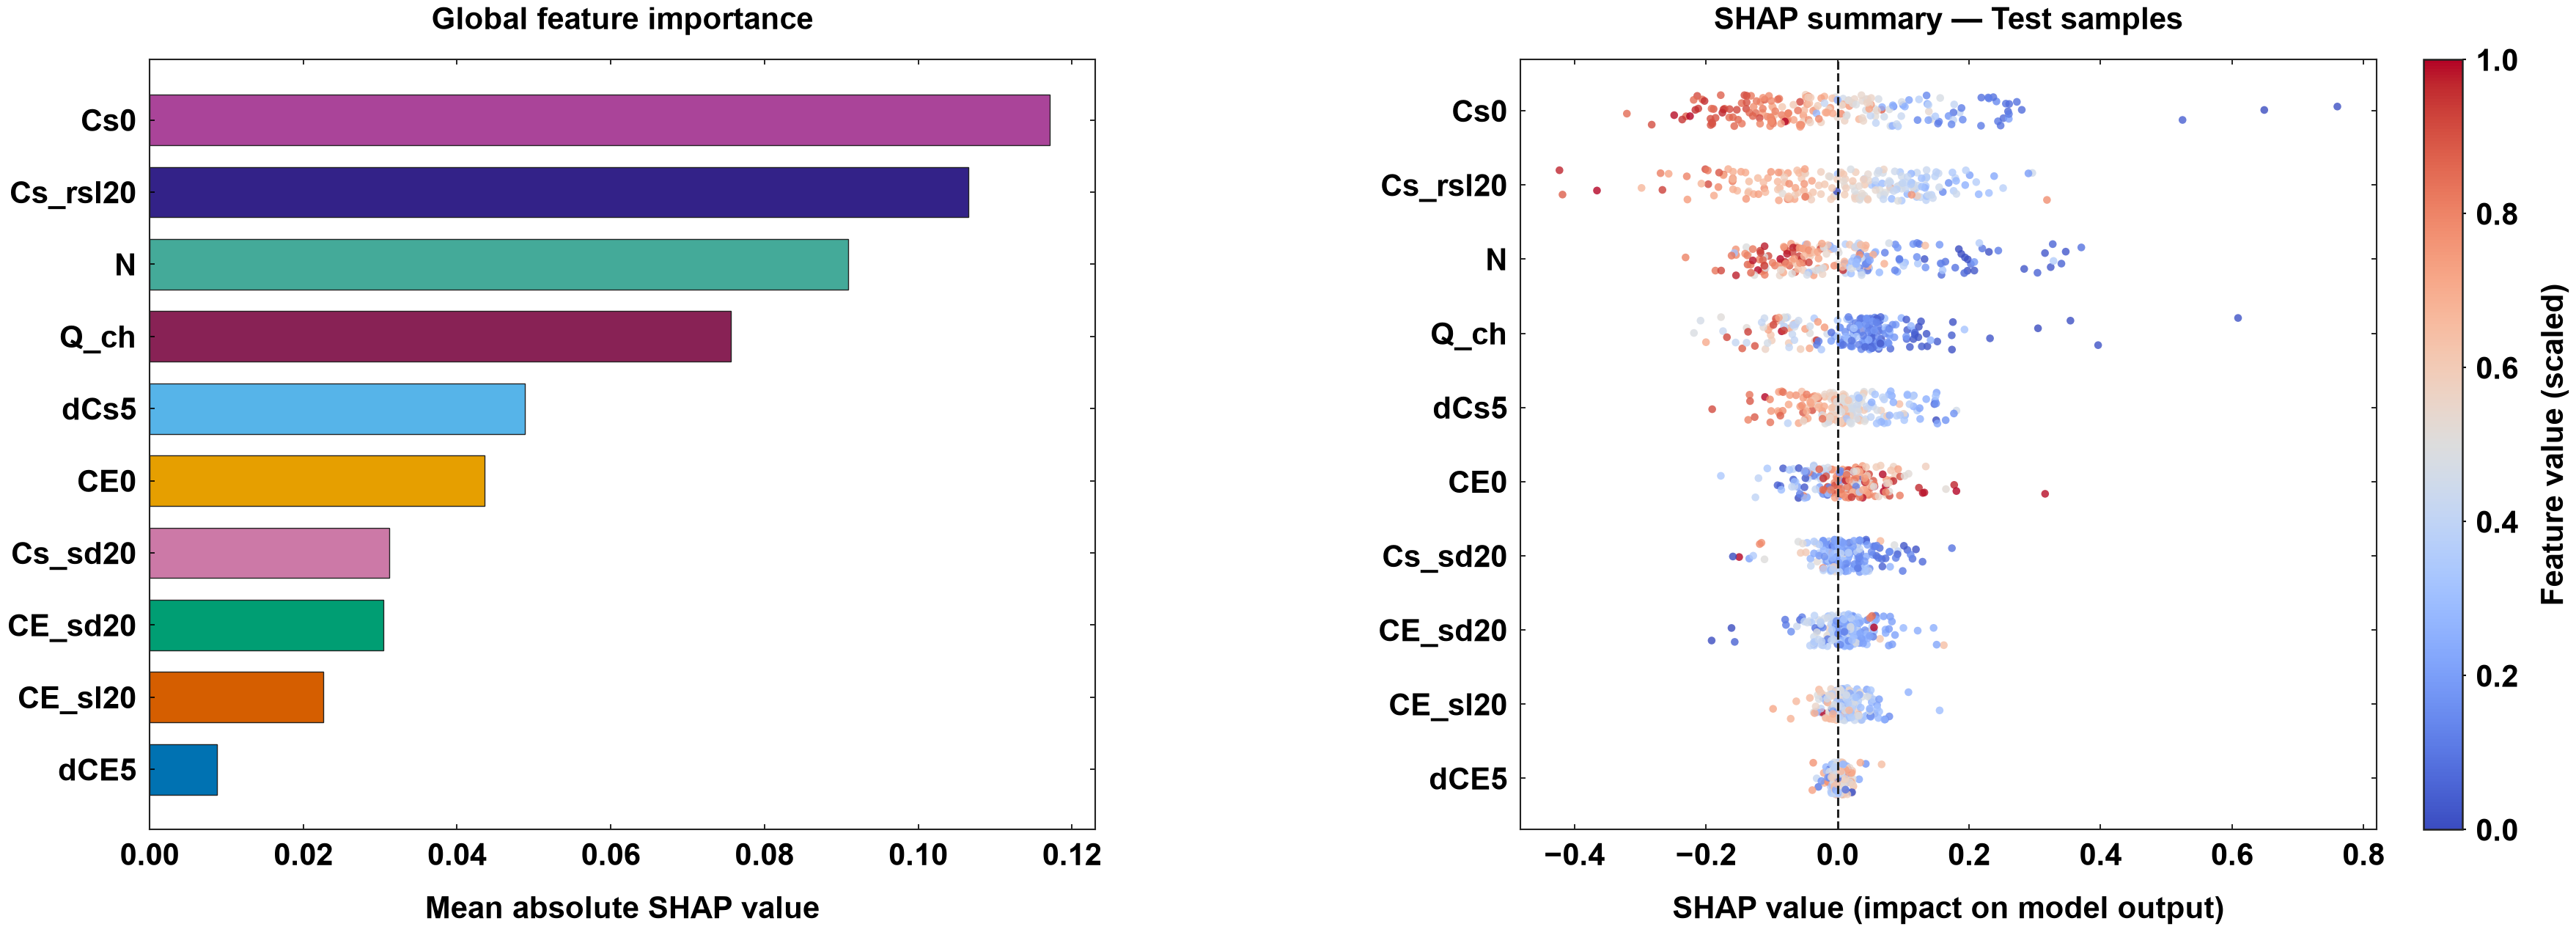

SHAP analysis completed.


In [84]:

# ============================================================
# STEP 12 — SHAP ANALYSIS
# ALL FONTS 30 PT, BOLD
# ============================================================

import shap
import matplotlib as mpl

FONT_SIZE = 30

# ============================================================
# 12.1 SHAP COMPUTATION
# ============================================================

background = X_train.sample(
    min(60, len(X_train)),
    random_state=SEED
)

explain_data = X_test.sample(
    min(200, len(X_test)),
    random_state=SEED
)

explainer = shap.Explainer(
    fitted_models[best_name].predict,
    shap.maskers.Independent(background),
    algorithm="permutation"
)

shap_explanation = explainer(
    explain_data,
    max_evals=2 * len(FEATURES) + 1
)

shap_values = np.asarray(shap_explanation.values)

mean_abs_shap = np.abs(shap_values).mean(axis=0)

importance_order = np.argsort(mean_abs_shap)

# Export importance data
shap_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_abs_SHAP": mean_abs_shap
}).sort_values(
    "Mean_abs_SHAP",
    ascending=False
)

shap_importance.to_excel(
    TABLE_DIR / "SHAP_Feature_Importance.xlsx",
    index=False
)

display(shap_importance)

# ============================================================
# 12.2 CREATE SHAP FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(40, 14)
)

# ============================================================
# LEFT — GLOBAL FEATURE IMPORTANCE
# ============================================================

sorted_features = np.array(FEATURES)[importance_order]
sorted_importance = mean_abs_shap[importance_order]

axes[0].barh(
    sorted_features,
    sorted_importance,
    color=[
        PALETTE[i % len(PALETTE)]
        for i in range(len(importance_order))
    ],
    edgecolor=COLOR_BLACK,
    linewidth=1.0,
    height=0.70
)

axes[0].set_xlabel(
    "Mean absolute SHAP value",
    fontsize=FONT_SIZE,
    fontweight="bold",
    labelpad=24
)

axes[0].set_title(
    "Global feature importance",
    fontsize=FONT_SIZE,
    fontweight="bold",
    pad=30
)

frame_axes(axes[0])

axes[0].tick_params(
    axis="both",
    labelsize=FONT_SIZE,
    pad=13
)

for label in (
    axes[0].get_xticklabels()
    + axes[0].get_yticklabels()
):
    label.set_fontweight("bold")

# ============================================================
# RIGHT — SHAP SUMMARY
# ============================================================

rng = np.random.default_rng(SEED)

ordered_features = importance_order[::-1]

for rank, j in enumerate(ordered_features):

    values = explain_data.iloc[:, j].to_numpy(
        dtype=float
    )

    shap_x = shap_values[:, j]

    valid = np.isfinite(values)

    if valid.any():
        vmin = np.min(values[valid])
        vmax = np.max(values[valid])
    else:
        vmin, vmax = 0.0, 1.0

    if vmax > vmin:
        normalized = (values - vmin) / (vmax - vmin)
    else:
        normalized = np.full(len(values), 0.5)

    normalized = np.where(
        np.isfinite(normalized),
        normalized,
        0.5
    )

    jitter = rng.uniform(
        -0.22,
        0.22,
        size=len(shap_x)
    )

    axes[1].scatter(
        shap_x,
        rank + jitter,
        c=normalized,
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        s=58,
        alpha=0.80,
        linewidths=0,
        rasterized=True
    )

axes[1].axvline(
    0,
    color=COLOR_BLACK,
    linestyle="--",
    linewidth=2.2
)

axes[1].set_yticks(
    range(len(ordered_features))
)

axes[1].set_yticklabels(
    np.array(FEATURES)[ordered_features],
    fontsize=FONT_SIZE,
    fontweight="bold"
)

axes[1].invert_yaxis()

axes[1].set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=FONT_SIZE,
    fontweight="bold",
    labelpad=24
)

axes[1].set_title(
    "SHAP summary — Test samples",
    fontsize=FONT_SIZE,
    fontweight="bold",
    pad=30
)

frame_axes(axes[1])

axes[1].tick_params(
    axis="both",
    labelsize=FONT_SIZE,
    pad=13
)

for label in (
    axes[1].get_xticklabels()
    + axes[1].get_yticklabels()
):
    label.set_fontweight("bold")

# ============================================================
# 12.3 SHAP COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    cmap="coolwarm",
    norm=mpl.colors.Normalize(0, 1)
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1],
    fraction=0.045,
    pad=0.05
)

cbar.set_label(
    "Feature value (scaled)",
    fontsize=FONT_SIZE,
    fontweight="bold",
    labelpad=22
)

cbar.ax.tick_params(
    labelsize=FONT_SIZE,
    width=1.5,
    pad=10
)

for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")

# ============================================================
# 12.4 ADJUST SPACING
# ============================================================

fig.subplots_adjust(
    left=0.12,
    right=0.91,
    bottom=0.15,
    top=0.90,
    wspace=0.45
)

# ============================================================
# 12.5 EXPORT
# ============================================================

export_figure(
    fig,
    "SHAP_Feature_Importance_Summary_30pt"
)

plt.show()
plt.close(fig)

print("SHAP analysis completed.")
